<a href="https://colab.research.google.com/github/JasmineLee7/movie-rec/blob/main/notebooks/01_ratings_matrix.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:
print("hello")

hello


In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## Part A: A Small Ratings Matrix

Rows represent users, and columns represent movies.
Ratings range from 1 to 5 stars. NaN represents a missing rating.

In [8]:
movies = ["Action 1", "Action 2", "Action 3",
          "Romance 1", "Romance 2", "Romance 3"]

users = ["Ana", "Ben", "Cal", "Dee", "Eve", "Fay"]

In [9]:
toy = np.array([
    [5, 4, 5, 1, np.nan, 2],       # Ana
    [4, np.nan, 5, 2, 1, 1],       # Ben
    [5, 5, np.nan, 1, 2, np.nan],  # Cal
    [1, 2, 1, 5, 4, np.nan],       # Dee
    [np.nan, 1, 2, 4, 5, 5],       # Eve
    [2, 1, np.nan, 5, np.nan, 4],  # Fay
])

toy_table = pd.DataFrame(toy, index=users, columns=movies)
toy_table

,Action 1,Action 2,Action 3,Romance 1,Romance 2,Romance 3
Ana,5.0,4.0,5.0,1.0,NaN,2.0
Ben,4.0,NaN,5.0,2.0,1.0,1.0
Cal,5.0,5.0,NaN,1.0,2.0,NaN
Dee,1.0,2.0,1.0,5.0,4.0,NaN
Eve,NaN,1.0,2.0,4.0,5.0,5.0
Fay,2.0,1.0,NaN,5.0,NaN,4.0


In [10]:
missing = np.isnan(toy).sum()
print("Missing entries:", missing, "out of", toy.size)

Missing entries: 8 out of 36


## Exercise 1: Predicting Missing Ratings

| User | Movie | Predicted rating |
|---|---|---|
| Ana | Romance 2 | 1 |
| Ben | Action 2 | 4 |
| Cal | Action 3 | 5 |
| Cal | Romance 3 | 1 |
| Dee | Romance 3 | 5 |
| Eve | Action 1 | 1 |
| Fay | Action 3 | 2 |
| Fay | Romance 2 | 5 |

Ana — Romance 2: I predicted 1 star because Ana gave Romance 1 a 1 and Romance 3 a 2, suggesting she dislikes romance movies. Ben has similar preferences: both rate action movies highly and romance movies poorly. Ben gave Romance 2 a 1, which supports my prediction.

Cal — Action 3: I predicted 5 stars because Cal gave both Action 1 and Action 2 a 5. Ana and Ben also enjoy action movies, and both gave Action 3 a 5. Their ratings support predicting that Cal would give it 5 stars too.

## Exercise 2: Adding a seventh user

Gus likes action movies and dislikes romance movies, like Ana, Ben, and Cal.
He rated four movies and has not rated Action 3 or Romance 3.

In [11]:
gus = np.array([5, 4, np.nan, 1, 2, np.nan])
toy7 = np.vstack([toy, gus])
users7 = users + ["Gus"]

toy7_table = pd.DataFrame(toy7, index=users7, columns=movies)
toy7_table

,Action 1,Action 2,Action 3,Romance 1,Romance 2,Romance 3
Ana,5.0,4.0,5.0,1.0,NaN,2.0
Ben,4.0,NaN,5.0,2.0,1.0,1.0
Cal,5.0,5.0,NaN,1.0,2.0,NaN
Dee,1.0,2.0,1.0,5.0,4.0,NaN
Eve,NaN,1.0,2.0,4.0,5.0,5.0
Fay,2.0,1.0,NaN,5.0,NaN,4.0
Gus,5.0,4.0,NaN,1.0,2.0,NaN


Gus gave Action 1 a 5, Action 2 a 4, Romance 1 a 1, and Romance 2 a 2.
His two missing ratings are Action 3 and Romance 3.

| User | Movie | Predicted rating |
|---|---|---|
| Gus | Action 3 | 5 |
| Gus | Romance 3 | 1 |

**Gus: Action 3: predicted 5.** Gus's observed ratings closely match Ana's
(5, 4, ..., 1) and Ben's (4, ..., 2, 1), who both like action and dislike
romance. Ana and Ben each gave Action 3 a 5. Dee and Eve, who have the opposite
taste, rated Action 3 only a 1 and a 2, which is consistent with Gus
being on the other side of that split.

**Gus: Romance 3: predicted 1.** Gus gave low ratings to Romance 1 and
Romance 2, so he seems to dislike the romance group. Ana (2) and Ben (1) also
rated Romance 3 low. Because Gus is slightly harsher on romance than Ana,
I predict 1 rather than 2.

## Part B: The MovieLens data

In [12]:
import os
import urllib.request
import zipfile

# Download the MovieLens 100k dataset if it doesn't exist
if not os.path.exists("ml-100k"):
    urllib.request.urlretrieve(
    "https://files.grouplens.org/datasets/movielens/ml-100k.zip",
        "ml-100k.zip"
    )
    zipfile.ZipFile("ml-100k.zip").extractall()

In [13]:
# Load the ratings data and display the first five rows
ratings = pd.read_csv(
    "ml-100k/u.data",
    sep="\t",
    names=["user", "item", "rating", "time"]
)
ratings.head()

,user,item,rating,time
0,196,242,3,881250949
1,186,302,3,891717742
2,22,377,1,878887116
3,244,51,2,880606923
4,166,346,1,886397596


In [14]:
# Count the ratings, users, and movies

print("Number of ratings:", len(ratings))
print("Number of users:", ratings["user"].nunique())
print("Number of movies:", ratings["item"].nunique())

Number of ratings: 100000
Number of users: 943
Number of movies: 1682


Average rating:  3.53


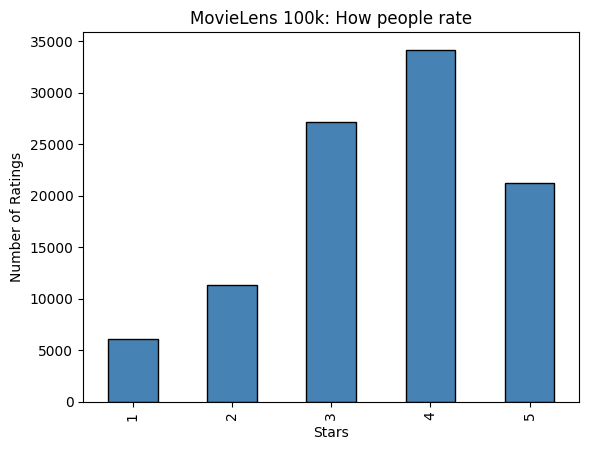

In [15]:
# Calculate the average rating and generate the bar chart

star_counts = ratings["rating"].value_counts().sort_index()
average_rating = ratings["rating"].mean()
print("Average rating: ", round(average_rating, 3))

star_counts.plot(kind="bar", color="steelblue", edgecolor="black")
plt.xlabel("Stars")
plt.ylabel("Number of Ratings")
plt.title("MovieLens 100k: How people rate")
plt.show()

# Part C: Building the user-by-movie matrix

Create a pivot table to reorganize the data into one row per user and one column per movie.

In [16]:
R = ratings.pivot_table (
  index="user",
  columns="item",
  values="rating"
)

The argument index="user" creates rows for users, columns="item" creates columns for movies, and values="rating" places the star rating in each matrix entry. Thus Rij means the rating given by user i to movie j. If the user has not rated that movie, the entry is NaN.

In [17]:
print("Matrix shape:", R.shape)
fraction_missing = R.isna().to_numpy().mean()
print("Fraction missing:", round(fraction_missing, 4))

Matrix shape: (943, 1682)
Fraction missing: 0.937


The shape is (943, 1682). The expression R.isna() returns a DataFrame object where all the values are replaced with a boolean value True for NA (not-a-number) values, and otherwise False. We convert it to a NumPy array with .to_numpy, and .mean() treats True as 1 and False as 0. Consequently, it reports the fraction of missing entries: approximately 0.9370, or 93.7%.

In [18]:
per_user = ratings.groupby("user").size()
print("Least active user:", per_user.min())
print("Median user:", int(per_user.median()))
print("Most active user:", per_user.max())

Least active user: 20
Median user: 65
Most active user: 737


groupby("user") groups all ratings belonging to the same person, and .size() counts each group.

# Part D: Which movies are rated most?

In [19]:
## Part D
# Load the movie IDs and titles
titles = pd.read_csv(
    "ml-100k/u.item",
    sep="|",
    encoding="latin-1",
    header=None,
    usecols=[0, 1],
    names=["item", "title"]
)

# Calculate the number of ratings and average rating for each movie
stats = ratings.groupby("item")["rating"].agg(["count", "mean"])

# Attach each movie's title using its movie ID
stats = stats.join(titles.set_index("item"))

# Select the five movies with the most ratings
top_five = stats.sort_values("count", ascending=False).head(5)

# Display the results rounded to two decimal places
top_five.round(2)

,count,mean,title
item,,,
50,583,4.36,Star Wars (1977)
258,509,3.80,Contact (1997)
100,508,4.16,Fargo (1996)
181,507,4.01,Return of the Jedi (1983)
294,485,3.16,Liar Liar (1997)


# Exercise 4: Find least common star rating

In [20]:
# Selects the column with the star ratings and counts rating frequency
star_counts = ratings["rating"].value_counts()
# Returns the star rating with the smallest count
print("Least common star rating:", star_counts.idxmin())
# Returns the count itself
print("Number of occurrences:", star_counts.min())

Least common star rating: 1
Number of occurrences: 6110


## Exercise 3: Count Missing Values

The np.isnan(toy) command creates a matrix of True and False values placing a True exactly where a rating is missing. The .sum() method then counts all those True values to give use th total number of missing ratings.

In [21]:
fraction_missing_toy = np.isnan(toy).mean()
print("Fraction missing in toy matrix:", fraction_missing_toy)

Fraction missing in toy matrix: 0.2222222222222222


## Exercise 5: User Averages

In [22]:
user_averages = ratings.groupby("user")["rating"].mean()

highest_user = user_averages.idxmax()
highest_average = user_averages.max()

print("User with highest average:", highest_user)
print("Highest average rating:", round(highest_average, 2))

User with highest average: 849
Highest average rating: 4.87


After calculating the averages, User 849 came out on top with a rating average of 4.87. Still, that result should be considered along with the number of ratings the user actually gave. If User 849 rated fewer movies than other users, their average is based on less information. Because of this, the highest average by itself is not enough to label someone the “most positive” user.

# Exercise 6

In the raw table ratings, each row represents one rating that a user
gave to one movie. The columns contain the user ID, movie ID, star
rating, and timestamp. A user can appear in multiple rows because
they can rate multiple movies.

In the matrix R, each row represents one user, and each column
represents one movie. Each entry contains that user's rating for
that movie. If the user has not rated the movie, the entry is NaN.

# Exercise 7

Why the SVD would be possible.** `np.linalg.svd` needs every entry of the matrix to be a real number. If no ratings were missing, R would be a complete 943 × 1682 numeric matrix, and every real matrix has an SVD, R = U Σ Vᵀ. So the computation would work.\n",

        Why it still might not solve the recommendation problem.
        There would be nothing left to predict.** Recommending means filling in ratings people haven't given yet. A complete matrix already contains every rating, so the SVD would only describe the data, not predict anything new
        Real data is never complete.** To run the SVD on our actual matrix (93.7% missing), we would have to fill the gaps with something like 0 or the average rating. The SVD treats those made-up values as real ratings, so it would mostly be fitting our guesses instead of what users actually said.\n",
        The full SVD fits noise too.** Ratings contain randomness, like mood or a one off opinion. The full rank SVD reproduces every rating exactly, noise included. To find the real patterns, we keep only the top k singular values (a low rank approximation), and choosing k is a separate problem.\n",

        The real goal is a low rank matrix that matches the ratings we did observe. Its values in the missing spots become our predictions.

# Exercise 8

The idea is that a few hidden factors explain most ratings. Each user has a \"taste\" score for each factor, each movie has a \"feature\" score, and a rating is high when the two match,
        
        "| Hidden factor | High value for a **user** | High value for a **movie**
        "| **Action vs. romance** | Enjoys action/adventure, tends to dislike romance | Mostly action: fights, chases, explosions |,
        "| **Mainstream vs. niche** | Prefers popular blockbusters everyone has seen | Widely watched, broad appeal (e.g., *Star Wars*) |,
        "| **Classic vs. modern** | Enjoys older films | Released decades ago or has a classic style |,
        ,
        "**How this connects to the SVD:** in R ≈ U_k Σ_k V_kᵀ, each row of U_k is a user's scores on the k factors, each row of V_k is a movie's scores, and the singular values in Σ_k show how much each factor matters. The SVD doesn't label the factors. We interpret them afterward by looking at which movies score highest and lowest on each one.